In [ ]:
!pip uninstall tensorflow-gpu tensorflow
!pip install tensorflow


Found existing installation: tensorflow 2.21.0
Uninstalling tensorflow-2.21.0:
  Would remove:
    /usr/local/bin/saved_model_cli
    /usr/local/bin/tf_upgrade_v2
    /usr/local/bin/tflite_convert
    /usr/local/bin/toco
    /usr/local/lib/python3.13/dist-packages/tensorflow-2.21.0.dist-info/*
    /usr/local/lib/python3.13/dist-packages/tensorflow/*
Proceed (Y/n)? y
  Successfully uninstalled tensorflow-2.21.0
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 572.9/572.9 MB 32.0 MB/s  0:00:16


In [ ]:
import tensorflow as tf
print(tf.__version__)

2.21.0


In [ ]:
## import some basic libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
dataset = pd.read_csv(r"/content/Churn_Modelling.csv")
dataset.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [ ]:
## DIvide the dataset into dependent and independent features
X = dataset.iloc[:,3:13]
Y = dataset.iloc[:,13]

In [ ]:
X.head()

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary
0,619,France,Female,42,2,0.00,1,1,1,101348.88
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58
2,502,France,Female,42,8,159660.80,3,1,0,113931.57
3,699,France,Female,39,1,0.00,2,0,0,93826.63
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10


In [ ]:
## feature engineering
geography = pd.get_dummies(X['Geography'],drop_first=True)
gender = pd.get_dummies(X['Gender'],drop_first=True)

In [ ]:
##Concatenate these variable with dataframe
X = X.drop(["Geography","Gender"],axis=1)
X.head()

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary
0,619,42,2,0.00,1,1,1,101348.88
1,608,41,1,83807.86,1,0,1,112542.58
2,502,42,8,159660.80,3,1,0,113931.57
3,699,39,1,0.00,2,0,0,93826.63
4,850,43,2,125510.82,1,1,1,79084.10


In [ ]:
X = pd.concat([X,geography,gender],axis=1)
X.head()

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Germany,Spain,Male
0,619,42,2,0.00,1,1,1,101348.88,False,False,False
1,608,41,1,83807.86,1,0,1,112542.58,False,True,False
2,502,42,8,159660.80,3,1,0,113931.57,False,False,False
3,699,39,1,0.00,2,0,0,93826.63,False,False,False
4,850,43,2,125510.82,1,1,1,79084.10,False,True,False


In [ ]:
## Spliting the dataset into training set and testing set
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X,Y,random_state=42,test_size=0.2)

In [ ]:
## feature scaling
from sklearn.preprocessing import StandardScaler
sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

In [ ]:
X_train.shape

(8000, 11)

In [ ]:
X_test.shape

(2000, 11)

In [ ]:
## Part 2 Here we create the ANN
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import LeakyReLU,PReLU,ReLU
from tensorflow.keras.layers import Dropout

## Dropout --------------> is like regulization in ml

In [ ]:
## Lets initialize the ANN ---------------->
classifier = Sequential()

In [ ]:
## Adding the input layer
classifier.add(Dense(units=11,activation="relu"))
classifier.add(Dropout(0.2))

In [ ]:
## Adding the first hidden layers
classifier.add(Dense(units=6,activation="relu"))
classifier.add(Dropout(0.3))

In [ ]:
## Adding the Second hidden layers
classifier.add(Dense(units=7,activation="relu"))

In [ ]:
## Adding the Output Layer
classifier.add(Dense(units=1,activation="sigmoid"))

In [ ]:
classifier.compile(optimizer='adam',loss='binary_crossentropy',metrics=['accuracy'])

In [ ]:
## Early Stopping
from tensorflow import keras
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    min_delta=0.0001,
    patience=20,
    verbose=1,
    mode="auto",
    baseline=None,
    restore_best_weights=False,
    start_from_epoch=0,
)


In [ ]:
model_history = classifier.fit(X_train,y_train,validation_split=0.33,batch_size=10,epochs=1000,callbacks=early_stopping)

Epoch 1/1000
536/536 ━━━━━━━━━━━━━━━━━━━━ 9s 10ms/step - accuracy: 0.8242 - loss: 0.4844 - val_accuracy: 0.8485 - val_loss: 0.3861
Epoch 2/1000
536/536 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8610 - loss: 0.3684 - val_accuracy: 0.8489 - val_loss: 0.3802
Epoch 3/1000
536/536 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8567 - loss: 0.3596 - val_accuracy: 0.8501 - val_loss: 0.3723
Epoch 4/1000
536/536 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8602 - loss: 0.3450 - val_accuracy: 0.8440 - val_loss: 0.3711
Epoch 5/1000
536/536 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8600 - loss: 0.3480 - val_accuracy: 0.8482 - val_loss: 0.3700
Epoch 6/1000
536/536 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8584 - loss: 0.3487 - val_accuracy: 0.8512 - val_loss: 0.3744
Epoch 7/1000
536/536 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8619 - loss: 0.3413 - val_accuracy: 0.8504 - val_loss: 0.3669
Epoch 8/1000
536/536 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8625 - loss: 0.3418 -

In [ ]:
model_history.history.keys()

dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss'])

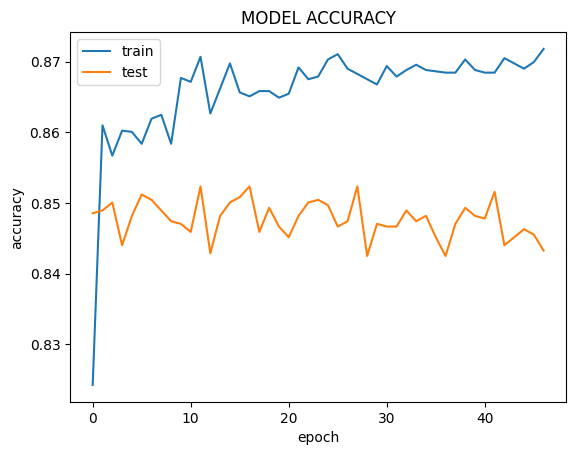

In [ ]:
## Summary history for accuracy
plt.plot(model_history.history['accuracy'])
plt.plot(model_history.history['val_accuracy'])
plt.title("MODEL ACCURACY")
plt.xlabel('epoch')
plt.ylabel('accuracy')
plt.legend(['train','test'],loc='upper left')
plt.show()

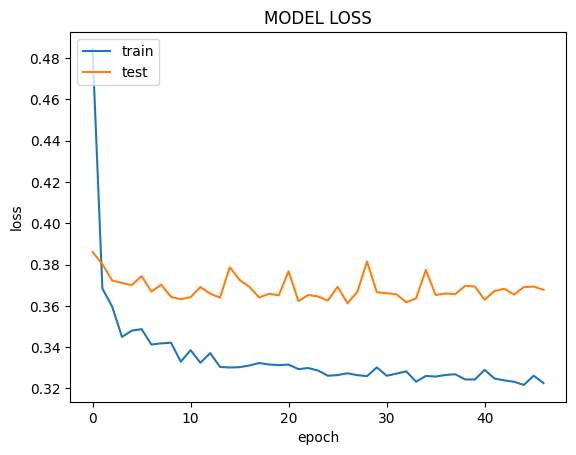

In [ ]:
## Summary history for loss
plt.plot(model_history.history['loss'])
plt.plot(model_history.history['val_loss'])
plt.title("MODEL LOSS")
plt.xlabel('epoch')
plt.ylabel('loss')
plt.legend(['train','test'],loc='upper left')
plt.show()

In [ ]:
## Part 3 - Making the predictions and evaluating the model
## Predicting the Test set results

y_pred = classifier.predict(X_test)
y_pred = (y_pred>=0.5)

63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step


In [ ]:
## make the confusion matrix
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test,y_pred)
cm

array([[1561,   46],
       [ 246,  147]])

In [ ]:
## Calculate the accuracy
from sklearn.metrics import accuracy_score
score = accuracy_score(y_test,y_pred)
score

0.854

In [ ]:
 ## get the weights
classifier.get_weights()

[array([[-3.93298566e-01, -2.40610078e-01,  9.24430937e-02,
          3.17233801e-01, -1.89624265e-01, -3.49772185e-01,
          8.39715749e-02, -4.83735889e-01, -1.53806293e-02,
         -3.47976238e-02, -1.16290845e-01],
        [-2.96304017e-01,  6.24775648e-01, -1.76540777e-01,
          6.79683089e-02, -1.82769969e-02, -1.01842754e-01,
         -6.27869070e-01,  9.31119546e-02, -9.05990541e-01,
          1.30635604e-01,  4.16090265e-02],
        [ 2.15403274e-01,  2.04634704e-02, -1.39164269e-01,
          3.69244516e-02, -1.21353760e-01, -2.35114813e-01,
         -8.13949779e-02, -7.36840535e-04,  6.19670190e-03,
         -2.11390898e-01,  1.56336129e-01],
        [ 2.48093396e-01, -5.65470979e-02,  1.24421351e-01,
          2.27936715e-01,  9.72004890e-01, -3.29320312e-01,
          1.08046770e-01, -3.69856954e-02, -5.05475663e-02,
         -1.05120444e+00, -3.80028009e-01],
        [-1.05264902e+00,  5.33267915e-01,  9.53743577e-01,
         -6.14229620e-01,  7.28739426e-02, -